# How Learning Rate Affects a Small CNN Trained on Fashion-MNIST

**Student:** [Kayla Nicole Jade T. Abris]  
**Course:** [DS4A]  
**Date:** [11/18/26]

## Research question

How does changing the learning rate affect the training loss, validation loss, and validation accuracy of a small Convolutional Neural Network (CNN) trained on Fashion-MNIST?

In this experiment, I will compare three learning rates: **0.0001, 0.001, and 0.01**. I will keep the dataset split, CNN architecture, optimizer, batch size, random seed, and number of epochs the same. This makes learning rate the only planned variable.

## 1. Background: what is a learning rate?

A learning rate is a setting that controls how large the optimizer's weight updates are during training. The CNN makes predictions, calculates a loss (a measure of prediction error), and uses gradients to update its weights.

A simplified gradient-descent update is:

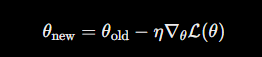

Here,  represents the model weights,  is the learning rate, and V  is the loss.

If the learning rate is very small, the model may learn slowly. If it is too large, updates may overshoot useful values and training can become unstable. A suitable value should reduce loss at a useful pace.

This experiment uses Adam. Learning-rate values that work well with Adam are not necessarily the same as values that work well with other optimizers.

## 2. Experiment design

### Dataset

Fashion-MNIST contains 70,000 grayscale images of clothing items. The original training set has 60,000 images and the test set has 10,000 images. Each image is 28 × 28 pixels and belongs to one of 10 classes.

To keep the experiment manageable, this notebook uses:
- 10,000 randomly selected images from the original training portion for model training.
- 6,000 images from the original training portion for validation (10% of the 60,000).
- The separate 10,000-image test set is not used to choose or compare learning rates.

### Controlled comparison

| Setting | Value |
|---|---:|
| Learning rates | 0.0001, 0.001, 0.01 |
| Optimizer | Adam |
| Batch size | 64 |
| Training subset | 10,000 images |
| Validation set | 6,000 images |
| Epochs | 10 |
| Random seed | 42 |
| CNN | Same small CNN in every run |
| Scheduler | None |
| Data augmentation | Off |

The same random seed is reset before each run. This helps keep the initial weights, data split, and shuffle sequence comparable. Small hardware-related differences may still occur.

**Independent variable:** learning rate.  
**Dependent measures:** training loss, validation loss, training accuracy, and validation accuracy.  
**Controlled variables:** all other settings in the table.

## 3. Import libraries and check the environment

The original class notebook uses PyTorch Lightning with Fashion-MNIST. The import below supports both the current `lightning` package and the older `pytorch_lightning` package name.

In [1]:
import logging
import random
import time
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

try:
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping
    from lightning.pytorch.loggers import CSVLogger
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.callbacks import EarlyStopping
    from pytorch_lightning.loggers import CSVLogger

warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Lightning:", L.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
Lightning: 2.6.6
GPU available: False


## 4. Set the experiment configuration

The `HParams` class stores the settings in one place. The architecture and training settings below are based on the supplied class notebook. The training subset and epoch count are set for this focused comparison.

In [2]:
@dataclass
class HParams:
    # Data
    data_dir: str = "./data"
    batch_size: int = 64
    val_fraction: float = 0.10
    train_subset: Optional[int] = 10_000
    augment: bool = False
    num_workers: int = 0

    # CNN architecture
    conv1_channels: int = 32
    conv2_channels: int = 64
    hidden_dim: int = 128
    activation: str = "relu"
    use_batchnorm: bool = True
    dropout: float = 0.25

    # Optimizer settings
    optimizer: str = "adam"
    lr: float = 0.001
    momentum: float = 0.9
    weight_decay: float = 0.0
    scheduler: str = "none"

    # Training
    max_epochs: int = 10
    patience: int = 100  # larger than max_epochs, so all runs use 10 epochs
    seed: int = 42


base_hp = HParams()
pd.Series(asdict(base_hp), name="Value").to_frame()

,Value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,10000
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


## 5. Load and prepare Fashion-MNIST

The training data is split into training and validation sets using a fixed seed. The validation set is used to compare the three learning rates. The test set is kept separate and is not used in this experiment's hyperparameter comparison.

In [3]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

FASHION_MEAN = (0.2860,)
FASHION_STD = (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp

        normalize = transforms.Normalize(FASHION_MEAN, FASHION_STD)
        self.eval_transform = transforms.Compose([
            transforms.ToTensor(),
            normalize
        ])

        augmentations = []
        if hp.augment:
            augmentations = [
                transforms.RandomCrop(28, padding=2),
                transforms.RandomHorizontalFlip()
            ]

        self.train_transform = transforms.Compose([
            *augmentations,
            transforms.ToTensor(),
            normalize
        ])

    def prepare_data(self):
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        train_view = datasets.FashionMNIST(
            self.hp.data_dir, train=True, transform=self.train_transform
        )
        eval_view = datasets.FashionMNIST(
            self.hp.data_dir, train=True, transform=self.eval_transform
        )

        total = len(train_view)
        n_val = int(total * self.hp.val_fraction)

        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(total, generator=generator).tolist()

        val_indices = indices[:n_val]
        train_indices = indices[n_val:]

        if self.hp.train_subset is not None:
            train_indices = train_indices[:self.hp.train_subset]

        self.train_ds = Subset(train_view, train_indices)
        self.val_ds = Subset(eval_view, val_indices)
        self.test_ds = datasets.FashionMNIST(
            self.hp.data_dir, train=False, transform=self.eval_transform
        )

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=shuffle,
            num_workers=self.hp.num_workers
        )

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, True)

    def val_dataloader(self):
        return self._loader(self.val_ds, 512, False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, False)


# Check the split sizes before training.
data_check = FashionMNISTDataModule(base_hp)
data_check.prepare_data()
data_check.setup()

print("Training images:", len(data_check.train_ds))
print("Validation images:", len(data_check.val_ds))
print("Test images (not used for tuning):", len(data_check.test_ds))

Training images: 10000
Validation images: 6000
Test images (not used for tuning): 10000


## 6. Define the small CNN

A CNN is a neural network designed to work with image data. Convolution layers learn image features, pooling layers reduce the spatial size, and the final fully connected layers use the learned features to predict one of the 10 clothing classes.

The architecture is kept the same for all three learning-rate runs.

In [4]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "gelu": nn.GELU,
    "tanh": nn.Tanh
}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        activation = ACTIVATIONS[hp.activation]
        c1 = hp.conv1_channels
        c2 = hp.conv2_channels

        def conv_block(in_channels, out_channels):
            layers = [
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
            ]
            if hp.use_batchnorm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers += [activation(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            conv_block(1, c1),
            conv_block(c1, c2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),
            activation(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_check = SmallCNN(base_hp)
parameter_count = sum(p.numel() for p in model_check.parameters() if p.requires_grad)
print(model_check)
print(f"Trainable parameters: {parameter_count:,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 421,834


## 7. Set up the Lightning model and training function

The model uses cross-entropy loss, which is commonly used for multi-class classification. Adam is selected as the optimizer. The learning rate is read from the configuration, so it can be changed without changing the CNN itself.

In [5]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def shared_step(self, batch, stage):
        images, labels = batch
        logits = self(images)
        loss = self.loss_fn(logits, labels)
        accuracy = (logits.argmax(dim=1) == labels).float().mean()

        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True)
        self.log(f"{stage}_acc", accuracy, on_step=False, on_epoch=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self.shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self.shared_step(batch, "val")

    def configure_optimizers(self):
        if self.hp.optimizer == "adam":
            return torch.optim.Adam(
                self.parameters(),
                lr=self.hp.lr,
                weight_decay=self.hp.weight_decay
            )
        raise ValueError("This experiment is configured to use Adam.")

In [6]:
def load_history(log_dir):
    metrics = pd.read_csv(Path(log_dir) / "metrics.csv")
    columns = [
        c for c in ["train_loss", "val_loss", "train_acc", "val_acc"]
        if c in metrics.columns
    ]
    return metrics.groupby("epoch")[columns].mean().reset_index()


def train_one_run(hp, run_name):
    # Reset the seed before each run for a fairer comparison.
    L.seed_everything(hp.seed, workers=True)

    data_module = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("learning_rate_logs", name=run_name)

    # patience is set above max_epochs, so early stopping should not
    # shorten any of the planned 10-epoch runs.
    early_stopping = EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=hp.patience
    )

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,
        accelerator="auto",
        devices=1,
        logger=logger,
        callbacks=[early_stopping],
        enable_checkpointing=False,
        enable_progress_bar=True,
        enable_model_summary=False,
        log_every_n_steps=10,
        deterministic=True
    )

    start_time = time.perf_counter()
    trainer.fit(model, datamodule=data_module)
    elapsed = time.perf_counter() - start_time

    history = load_history(logger.log_dir)
    return history, elapsed

## 8. Run the learning-rate experiments

The three values are separated by a factor of ten. This is a simple logarithmic comparison: it helps show whether training changes when the step size is made smaller or larger.

Each run starts with the same seed and uses the same base configuration. Only `lr` changes.

In [7]:
learning_rates = [0.0001, 0.001, 0.01]

experiment_results = {}

for learning_rate in learning_rates:
    label = f"lr={learning_rate:g}"
    print("\nRunning:", label)

    run_hp = replace(base_hp, lr=learning_rate)
    history, seconds = train_one_run(
        run_hp,
        run_name=label.replace("=", "_")
    )

    experiment_results[label] = {
        "learning_rate": learning_rate,
        "history": history,
        "seconds": seconds
    }

    print(f"Completed {label} in {seconds:.1f} seconds")
    print(f"Best validation accuracy: {history['val_acc'].max():.4f}")

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



Running: lr=0.0001
Sanity Checking: |          | 0/? [00:00<?, ?it/s]

C:\Users\Aldwy\anaconda3\envs\hyperparams\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch 0: 100%|██████████| 157/157 [00:05<00:00, 26.29it/s, v_num=0]        
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 1: 100%|██████████| 157/157 [00:06<00:00, 26.03it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 2: 100%|██████████| 157/157 [00:05<00:00, 26.81it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 3: 100%|██████████| 157/157 [00:05<00:00, 26.77it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 4: 100%|██████████| 157/157 [00:06<00:00, 25.60it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 5: 100%|██████████| 157/157 [00:06<00:00, 24.40it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 6

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 9: 100%|██████████| 157/157 [00:08<00:00, 19.38it/s, v_num=0]

... (6 outputs left out)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Epoch 0: 100%|██████████| 157/157 [00:06<00:00, 24.93it/s, v_num=0]        
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 1: 100%|██████████| 157/157 [00:05<00:00, 27.43it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 2: 100%|██████████| 157/157 [00:05<00:00, 26.65it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 3: 100%|██████████| 157/157 [00:05<00:00, 26.27it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 4: 100%|██████████| 157/157 [00:05<00:00, 26.82it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 5: 100%|██████████| 157/157 [00:06<00:00, 25.08it/s, v_num=0]     
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 6

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 9: 100%|██████████| 157/157 [00:08<00:00, 18.12it/s, v_num=0]
Completed lr=0.01 in 82.4 seconds
Best validation accuracy: 0.8748


## 9. Figure 1 — Training and validation loss

Loss measures how far the model's predictions are from the correct labels. Lower loss is generally better. The training curve shows performance on the examples used to update the model, while the validation curve shows performance on held-out examples.

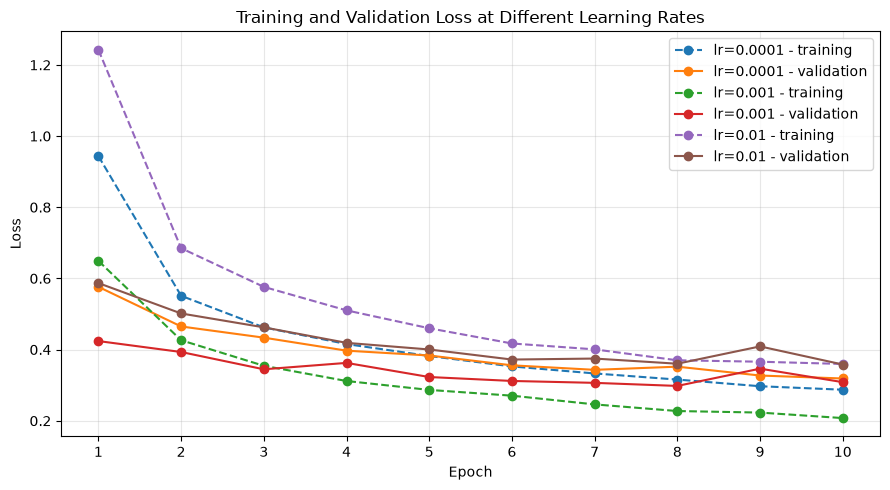

In [8]:
plt.figure(figsize=(9, 5))

for label, result in experiment_results.items():
    history = result["history"]
    epochs = history["epoch"] + 1

    plt.plot(
        epochs, history["train_loss"],
        marker="o", linestyle="--",
        label=f"{label} - training"
    )
    plt.plot(
        epochs, history["val_loss"],
        marker="o", linestyle="-",
        label=f"{label} - validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss at Different Learning Rates")
plt.xticks(range(1, base_hp.max_epochs + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_rate_loss.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 1 caption:** Training and validation loss across 10 epochs for learning rates 0.0001, 0.001, and 0.01. Dashed lines represent training loss and solid lines represent validation loss.

**My observation (complete after running):** The learning rate that showed the fastest decrease in validation loss was ________. The curve for ________ was (more stable / less stable) because ________.

## 10. Figure 2 — Training and validation accuracy

Accuracy is the percentage of images classified correctly. Higher accuracy is better, but validation accuracy is more useful than training accuracy when comparing how well the model performs on images it did not train on.

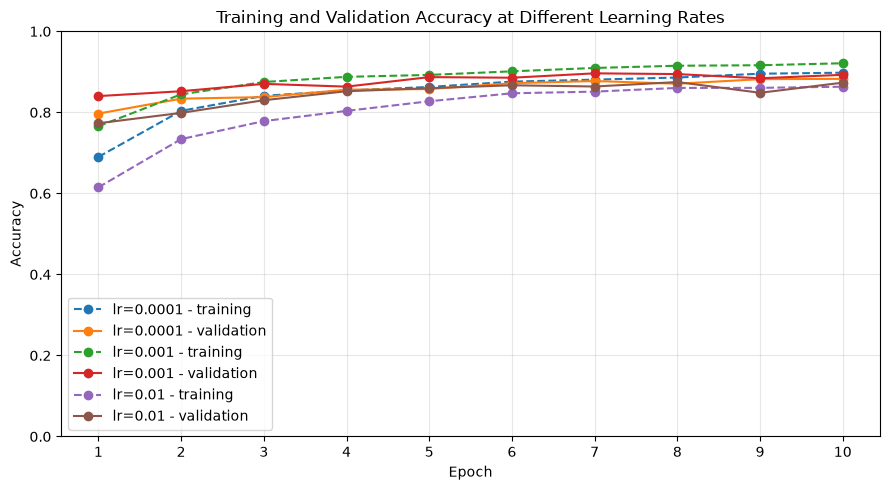

In [9]:
plt.figure(figsize=(9, 5))

for label, result in experiment_results.items():
    history = result["history"]
    epochs = history["epoch"] + 1

    plt.plot(
        epochs, history["train_acc"],
        marker="o", linestyle="--",
        label=f"{label} - training"
    )
    plt.plot(
        epochs, history["val_acc"],
        marker="o", linestyle="-",
        label=f"{label} - validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy at Different Learning Rates")
plt.xticks(range(1, base_hp.max_epochs + 1))
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_rate_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 2 caption:** Training and validation accuracy across 10 epochs for the three learning rates. Dashed lines represent training accuracy and solid lines represent validation accuracy.

**My observation (complete after running):** The highest validation accuracy was reached by ________. Its best validation accuracy was ________ (convert the decimal to a percentage when writing the blog).

## 11. Results table

The table below is calculated from the recorded training histories. `Best validation accuracy` is the highest validation accuracy reached during the run. `Lowest validation loss` is the lowest validation loss reached during the run. These are validation measures, not test-set results.

In [10]:
rows = []

for label, result in experiment_results.items():
    history = result["history"]

    rows.append({
        "Learning rate": result["learning_rate"],
        "Best validation accuracy": history["val_acc"].max(),
        "Lowest validation loss": history["val_loss"].min(),
        "Final training loss": history["train_loss"].iloc[-1],
        "Final validation loss": history["val_loss"].iloc[-1],
        "Final validation accuracy": history["val_acc"].iloc[-1],
        "Epochs completed": len(history),
        "Training time (seconds)": round(result["seconds"], 1)
    })

results_table = pd.DataFrame(rows).sort_values("Learning rate")
display(
    results_table.style.format({
        "Best validation accuracy": "{:.4f}",
        "Lowest validation loss": "{:.4f}",
        "Final training loss": "{:.4f}",
        "Final validation loss": "{:.4f}",
        "Final validation accuracy": "{:.4f}",
        "Training time (seconds)": "{:.1f}"
    })
)

results_table.to_csv("learning_rate_results.csv", index=False)

,Learning rate,Best validation accuracy,Lowest validation loss,Final training loss,Final validation loss,Final validation accuracy,Epochs completed,Training time (seconds)
0,0.000100,0.8827,0.3188,0.2873,0.3188,0.8827,10,83.0
1,0.001000,0.8963,0.2979,0.2076,0.3085,0.8927,10,82.0
2,0.010000,0.8748,0.3581,0.3596,0.3581,0.8733,10,82.4


**Table 1 caption:** Validation and training metrics for each learning-rate setting. The table is generated from the experiment histories.


## 12. Discussion
The purpose of this experiment was to find out how the learning rate affects the training of a small Convolutional Neural Network (CNN) on Fashion-MNIST. I compared three learning rates: 0.0001, 0.001, and 0.01. The same CNN, dataset split, Adam optimizer, batch size, random seed, and number of epochs were used in all runs. This made the learning rate the main setting being changed.

The results show that 0.001 performed best overall among the three values tested. It reached the highest validation accuracy of 89.63% and the lowest validation loss of 0.2979. Its final validation accuracy was 89.27%, and its final validation loss was 0.3085. The fact that it achieved the strongest validation results suggests that this learning rate provided a useful balance between making progress and avoiding overly large weight updates.

The smallest learning rate, 0.0001, achieved a best validation accuracy of 88.27% and a lowest validation loss of 0.3188. Its loss decreased gradually across the epochs. A small learning rate makes smaller updates to the model's weights. This can make learning more gradual, but it may also mean that the model needs more epochs to reach its best performance. In this 10-epoch experiment, it performed well but did not outperform 0.001.

The largest learning rate, 0.01, achieved a best validation accuracy of 87.48% and a lowest validation loss of 0.3581. Its training loss fell quickly at the beginning, but its validation-loss curve was less consistent near the later epochs. For example, the validation loss rose around epoch 9 before falling again at epoch 10. This pattern is consistent with the idea that larger updates can make it harder for the model to settle on useful weight values. However, this experiment tested only one run for each setting, so the result should be treated as evidence from this particular run rather than proof that 0.01 will always perform worse.

The accuracy graph also helps explain the comparison. All three settings improved in accuracy during training. The 0.001 setting reached the highest validation accuracy, while the 0.0001 setting finished close behind. The 0.01 setting improved quickly at first but ended with the lowest validation accuracy of the three. This shows why it is important to examine validation performance, not only training performance. A model can become more accurate on its training examples without improving by the same amount on examples it did not train on.

There is also a gap between training and validation performance. For 0.001, the final training loss was 0.2076, compared with a final validation loss of 0.3085. Its final training accuracy was higher than its validation accuracy as well. This gap may indicate some overfitting: the model learned the training examples better than the held-out validation examples. It does not mean the model failed, because the validation accuracy remained high, but it is a reason to be careful when interpreting the result.

Overall, the experiment supports the idea that the learning rate is an important hyperparameter. A value that is too small may make learning slower, while a value that is too large may lead to less stable validation results. For this CNN, dataset subset, optimizer, and training duration, 0.001 was the strongest of the three tested values. It should not be described as the best learning rate for every CNN or every dataset.
Limitations
This experiment has several limitations. First, it used 10,000 training images rather than the full 60,000-image training portion of Fashion-MNIST. Second, each learning rate was tested with only one random seed, so small changes in initialization or data order could affect the results. Third, only three learning-rate values were compared, and all runs used the Adam optimizer for 10 epochs. A different number of epochs, optimizer, or model could produce a different outcome. Finally, the separate test set was not evaluated, because the purpose here was to compare hyperparameters using validation data. A future experiment could repeat each setting with multiple seeds, test more learning rates around 0.001, and evaluate the final selected model on the test set once the comparison is complete.
What I learned
Through this experiment, I learned that changing one hyperparameter can affect both the speed of training and the model's ability to perform on validation data. I also learned that the highest training accuracy is not enough to decide which model is best. Validation accuracy and validation loss provide a better basis for comparing settings that the model did not train on. The result encouraged me to look at both the numerical table and the curves instead of relying on only one metric.

## 13. Conclusion

In this experiment, I learned that the learning rate plays an important role in how a CNN learns and performs. Among the three learning rates tested, **0.001 achieved the best results**, with a validation accuracy of **89.63%** and a validation loss of **0.2979**.

The results showed that using a smaller or larger learning rate does not always lead to better performance. Choosing a suitable value helps the model learn more effectively and make better predictions.

This experiment helped me understand why learning rate is an important hyperparameter in deep learning. However, more experiments are needed to determine whether 0.001 would remain the best choice under different training conditions.

## 14. References
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms. arXiv:1708.07747. https://arxiv.org/abs/1708.07747
- PyTorch. (n.d.). PyTorch documentation. https://pytorch.org/docs/stable/index.html
- Lightning AI. (n.d.). PyTorch Lightning documentation. https://lightning.ai/docs/pytorch/stable/

## 15. AI Use Acknowledgment
I used ChatGPT to help organize and review parts of this notebook, explain the learning-rate concepts in simpler language, troubleshoot code and environment issues, and improve the wording of the discussion. I ran the experiment in my own environment and used the results generated by my notebook. I reviewed the explanations and results before including them. (I will follow my instructor's requirements for permitted AI assistance and disclosure.)